#Group 2
Swostika Lama = 2424852

Jiya Jameela Kanhirathan Poyil = 2414377

Sachin Bhandari = 2324467

Puntawat Subhamani = 2412117

In [19]:
!pip install numpy pandas matplotlib scikit-learn keras tensorflow

# 1. Meet the concrete dataset

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import Sequential, Input
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(32)

concrete_data = pd.read_csv(
    "https://raw.githubusercontent.com/AI-Learning-Repo/resources/refs/heads/main/datasets/concrete.csv"
)

In [21]:
# Display the first five rows and the column names.
concrete_data[:5]

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [22]:
# Find the number of rows and columns.
concrete_data.shape

(1030, 9)

In [23]:
# Check for missing values with .isna().sum()
concrete_data.isna().sum()

,0
Cement,0
BlastFurnaceSlag,0
FlyAsh,0
Water,0
Superplasticizer,0
CoarseAggregate,0
FineAggregate,0
Age,0
CompressiveStrength,0


**Identify the target and the number of input features.**

<details><summary>Answers </summary>

Target: `CompressiveStrength`

Number of input features: 8
</details>

# 2. Separate input features and target

In [24]:
concrete_features = concrete_data.drop(columns=["CompressiveStrength"])
concrete_target = concrete_data[["CompressiveStrength"]]

**Question: What would go wrong if CompressiveStrength were also included among the features?**
<details><summary>Answer</summary>

Target will leak into training dataset
</details>

# 3. Split into training, validation, and test sets

In [25]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    concrete_features, concrete_target, test_size=0.2, random_state=32
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=32
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (659, 8)
Validation: (165, 8)
Test: (206, 8)


**Questions**

1. Why do we keep a separate validation set?
2. Why should we not repeatedly evaluate architectures on the test set?

<details><summary><strong>Answer</strong></summary>

1. So that validation set used while training does not leak into training set
2. Because then test set can no longer be unbiased data because we evaluate the performance of the model on it???
</details>

# 4. Standardize the input features


In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)



In [27]:
print('Scaled training shape :', X_train_scaled.shape)
print('Scaled validation shape :', X_val_scaled.shape)
print('Scaled test shape :', X_test_scaled.shape)

Scaled training shape : (659, 8)
Scaled validation shape : (165, 8)
Scaled test shape : (206, 8)


In [28]:
X_train_scaled.mean(axis=0)

array([-3.12681932e-16,  1.63079801e-16, -7.00838814e-17, -8.62570848e-17,
       -4.31285424e-17, -2.69553390e-17, -1.47176151e-15, -4.04330085e-17])

**Questions**

1. Why is `fit_transform()` applied only to training data?
2. What is the approximate mean of each **scaled training feature**?
3. Why should we not scale validation and test data by fitting a new scaler on each set?

<details>
<summary><strong>Answer</strong></summary>

1. Inorder to prevent data leakage.

2. The approximate mean of each **Scaled training feature** is close to zero.

3. Because using same values validation and test samples keep representation consistent and prevent data leakage.

</details>

# 5. Build the baseline MLP


In [29]:
concrete_model = Sequential( name = 'concrete_MLP')
concrete_model.add(Input(shape=(X_train_scaled.shape[1],)))
concrete_model.add(Dense(128, activation='relu'))
concrete_model.add(Dense(64, activation='relu'))
concrete_model.add(Dense(1))

concrete_model.summary()

Model: "concrete_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

**Questions**

1. Why is there one output neuron?
2. Why is the output **linear**, unlike the sigmoid output used for XOR?
3. Calculate the total number of trainable weights and biases.

<details>
<summary><strong>Answer</strong></summary>
1. Because it predicts one numerical value.
2. The default **linear** activation allows output beyond 0 and 1 which is suitable for regression but sigmoid uses a binary class score
3. | Dense layer | Calculation | Parameters |
|---|---|---:|
| 8 → 128 | `(8 × 128) + 128` | 1,152 |
| 128 → 64 | `(128 × 64) + 64` | 8,256 |
| 64 → 1 | `(64 × 1) + 1` | 65 |
| **Total** | | **9,473** |


</details>


# 6. Compile the MLP


In [30]:
concrete_model_compile = concrete_model.compile(
    optimizer='adam', loss='mean_squared_error', metrics = ['mae']
)

**Question:** Why is classification accuracy inappropriate here? What are the units of MSE and MAE?

<details>
<summary><strong>Answer</strong></summary>

Because it represents continuous regression.

Unit of MSE MPa2 and MAE = MPa

</details>


#7. Train the baseline model

In [31]:
# Train the baseline model
history_concrete = concrete_model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

print("Final training MAE:", round(history_concrete.history["mae"][-1], 2))
print("Final validation MAE:", round(history_concrete.history["val_mae"][-1], 2))

Final training MAE: 4.22
Final validation MAE: 5.41


**Questions**
1. What does an epoch mean?

<details>
<summary><strong>Answer</strong></summary>An epoch is one complete pass through the entire training dataset. During one epoch, the model sees every training example once and updates its weights.

</details>

 2. What do training MAE and validation MAE measure?

<details>
<summary><strong>Answer</strong></summary>Training MAE measures the average absolute error (in MPa) on the data the model is actively learning from.

Validation MAE measures the average absolute error (in MPa) on a separate set of data the model has not trained on. It is used to check if the model generalizes well to new data.</details>

 3. Does a lower training loss guarantee a lower validation loss?

<details>
<summary><strong>Answer</strong></summary>No. A model can memorize the training data (lowering training loss) while failing to learn general patterns,</details>

#8. Visualize training and validation results


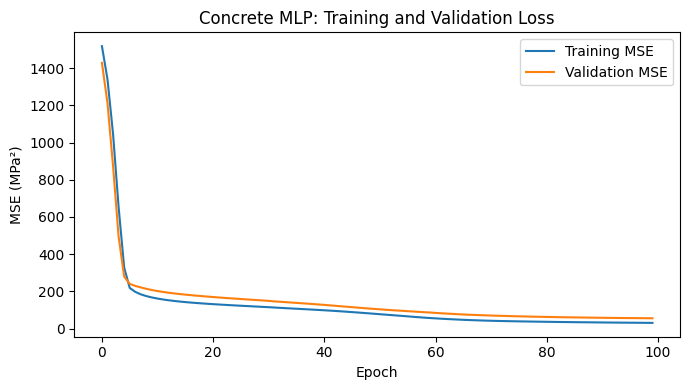

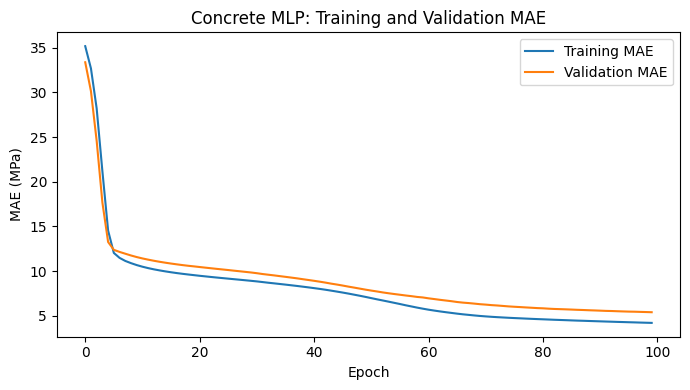

In [32]:
# Plot MSE
plt.figure(figsize=(7, 4))
plt.plot(history_concrete.history["loss"], label="Training MSE")
plt.plot(history_concrete.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (MPa²)")
plt.title("Concrete MLP: Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

# Plot MAE
plt.figure(figsize=(7, 4))
plt.plot(history_concrete.history["mae"], label="Training MAE")
plt.plot(history_concrete.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (MPa)")
plt.title("Concrete MLP: Training and Validation MAE")
plt.legend()
plt.tight_layout()
plt.show()

**Discussion**

1. Does validation loss follow the same pattern as training loss?
<details>
<summary><strong>Answer</strong></summary>Yes. In both the MSE and MAE graphs, the orange line (Validation) closely mirrors the blue line (Training)</details>
2. What might it mean if training loss decreases while validation loss increases?
<details>
<summary><strong>Answer</strong></summary>If the blue line kept dropping but the orange line started curving upward, it would mean the model is overfitting. The model would be memorizing the specific training examples (including their noise) rather than learning the general underlying rules of concrete strength. Because your validation loss is still decreasing (or flat) at epoch 100, your model is not overfitting.

</details>
3. Why does an MAE plot have more intuitive units than an MSE plot?
<details>
<summary><strong>Answer</strong></summary>Validation curves may fluctuate. A sustained increase in validation loss while training loss decreases may indicate overfitting; one noisy epoch is not conclusive. MAE is directly expressed in MPa, while MSE is expressed in squared MPa. No particular curve shape or epoch number is guaranteed.

</details>

#9. Challenge: Experiment and select a model before testing


In [33]:
keras.utils.set_random_seed(32)

candidate_model = Sequential(name="Concrete_Candidate")
candidate_model.add(Input(shape=(X_train_scaled.shape[1],)))
candidate_model.add(Dense(64, activation="relu"))
candidate_model.add(Dense(32, activation="relu"))
candidate_model.add(Dense(1))

candidate_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)
candidate_history = candidate_model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

baseline_val_mae = history_concrete.history["val_mae"][-1]
candidate_val_mae = candidate_history.history["val_mae"][-1]
print(f"Baseline final validation MAE: {baseline_val_mae:.2f} MPa")
print(f"Candidate final validation MAE: {candidate_val_mae:.2f} MPa")

if candidate_val_mae < baseline_val_mae:
    final_model = candidate_model
    print("Selected candidate using validation MAE.")
else:
    final_model = concrete_model
    print("Selected baseline using validation MAE.")

Baseline final validation MAE: 5.41 MPa
Candidate final validation MAE: 6.21 MPa
Selected baseline using validation MAE.


**Discussion:** Does a larger model always win? Does more training always improve validation results? Can one run demonstrate that one architecture is universally better?

<details>
<summary><strong>Answer</strong></summary> No. A larger model (more neurons/layers) has more parameters and can memorize training data, but it may overfit and perform worse on validation data.
No. Neural networks are sensitive to random weight initialization, and the validation split itself is just a random sample. One run is only a single data point. Rigorous comparison requires running each architecture multiple times with different random seeds and averaging the results.
</details>

# 10. Final evaluation on the test set

In [34]:
test_mse, test_mae = final_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Final test MSE: {test_mse:.2f} MPa²")
print(f"Final test MAE: {test_mae:.2f} MPa")

Final test MSE: 40.92 MPa²
Final test MAE: 4.69 MPa


**If test MAE is 5 MPa, does that mean every individual prediction is within 5 MPa of its target?**
> No. A test MAE of 5 MPa means that the average absolute difference between predicted and actual compressive strength is 5 MPa. Individual predictions may have errors greater or smaller than 5 MPa.

> MAE measures the average absolute prediction error, not the maximum error.
In my experiment, the test MAE was 4.69 MPa, meaning the model's predictions differed from actual concrete strengths by an average of 4.69 MPa. Individual prediction errors can be larger or smaller than this average.

# 11. Inspect predictions and individual errors

In [37]:
# Generate predictions as a 1D array
predictions = final_model.predict(
    X_test_scaled,
    verbose=0
).flatten()

# Create DataFrame
results = pd.DataFrame({
    "Actual (MPa)": np.asarray(y_test).flatten(),
    "Predicted (MPa)": predictions
})

# Calculate absolute errors
results["Absolute error (MPa)"] = (
    results["Actual (MPa)"] - results["Predicted (MPa)"]
).abs()

# Display first 10 predictions
print(results.head(10).round(2))

   Actual (MPa)  Predicted (MPa)  Absolute error (MPa)
0         18.28        30.500000                 12.22
1         31.02        37.290001                  6.27
2         12.84        14.170000                  1.33
3         53.90        39.070000                 14.83
4         39.70        34.980000                  4.72
5         31.12        33.869999                  2.75
6         61.92        62.060001                  0.14
7         56.81        56.790001                  0.02
8         40.87        40.799999                  0.07
9         43.50        41.680000                  1.82


In [38]:
shown = results.head(10)

print("Smallest displayed error:")
print(shown.loc[shown["Absolute error (MPa)"].idxmin()])

print("\nLargest displayed error:")
print(shown.loc[shown["Absolute error (MPa)"].idxmax()])

Smallest displayed error:
Actual (MPa)            56.81000
Predicted (MPa)         56.78717
Absolute error (MPa)     0.02283
Name: 7, dtype: float64

Largest displayed error:
Actual (MPa)            53.900000
Predicted (MPa)         39.067101
Absolute error (MPa)    14.832899
Name: 3, dtype: float64




**Smallest absolute error (row 7):**
- Actual strength: 56.81 MPa
- Predicted strength: 56.79 MPa
- Absolute error: **0.02 MPa**

**Largest absolute error (row 3):**
- Actual strength: 53.90 MPa
- Predicted strength: 39.07 MPa
- Absolute error: **14.83 MPa**

### 2. Does the model predict all mixtures equally well?

No. The prediction errors vary between concrete mixtures. Among the first ten predictions, the smallest absolute error was **0.02 MPa**, while the largest was **14.83 MPa**. This indicates that the model predicts some mixtures more accurately than others.

### 3. What measured or unmeasured factors might contribute to errors?

Prediction errors may be influenced by differences in ingredient proportions, curing age, material variability, curing conditions, and measurement differences. Some factors are not represented in the dataset, which may limit the model's prediction accuracy.

### 4. Why should this educational model not replace laboratory strength testing?

The model estimates compressive strength based on historical data and cannot guarantee the actual strength of a concrete mixture. Laboratory testing remains necessary to verify concrete strength for engineering and safety purposes.

## Conclusion and Reflection

### Exit Question: What are the key differences among the XOR, cereal, and concrete models in their targets, output layers, and evaluation metrics?

| Model | Problem Type | Target | Output Activation | Loss Function | Evaluation Metric |
|---|---|---|---|---|---|
| XOR | Binary classification | 0 or 1 | Sigmoid | Binary cross-entropy | Accuracy |
| Cereal | Regression | Numerical cereal rating | Linear | MSE | MAE (rating points) |
| Concrete | Regression | Compressive strength (MPa) | Linear | MSE | MAE (MPa) |

### Reflection

In this activity, I applied the MLP regression workflow from Activity 3 to predict concrete compressive strength. I practiced data preparation, feature standardization, neural network training, and model comparison using validation MAE.

The selected model achieved a **test MSE of 40.92 MPa² and MAE of 4.69 MPa**. Individual predictions showed varying errors, demonstrating that a low average error does not guarantee accurate predictions for every sample.

I also learned the importance of separating training, validation, and test datasets to prevent data leakage and ensure reliable model evaluation.

### Conclusion

Activity 4 demonstrated how multi-layer perceptrons can be applied to regression problems. Unlike XOR classification, the cereal and concrete models use linear output layers to predict continuous numerical values.

The experiment reinforced the importance of preprocessing, training, validation, model selection, and error analysis. Although the model learned relationships between concrete ingredients, curing age, and compressive strength, its predictions remain estimates and cannot replace laboratory testing for engineering decisions.